# Attention Mechanism — PyTorch Notebook

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

np.random.seed(42)
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.14.0+cpu
Device: cpu


## 1. The basic idea

Attention lets each token combine information from other tokens according to relevance scores.

- **Query (Q):** what this token is looking for.
- **Key (K):** what each token offers for matching.
- **Value (V):** the information that will be combined.

The output includes a weighted combination of the Value vectors. The weights sum to 1 across the tokens being attended to.

In [2]:
# 3 tokens, each represented by a 4-dimensional vector.
tokens = ["The", "cat", "sleeps"]
Q = torch.tensor([[1.0, 0.0, 1.0, 0.0]])          # one query (shape: 1 x 4)

K = torch.tensor([[1.0, 0.0, 0.0, 1.0],
                  [1.0, 1.0, 0.0, 0.0],
                  [0.0, 0.0, 1.0, 1.0]])           # keys (shape: 3 x 4)
                  
V = torch.tensor([[10.0, 0.0],
                  [0.0, 20.0],
                  [5.0, 5.0]])                     # values (shape: 3 x 2)

scores = Q @ K.T
weights = torch.softmax(scores / math.sqrt(K.shape[-1]), dim=-1)
context = weights @ V

print("Scores:", scores)
print("Attention weights:", weights)
print("Sum of weights:", weights.sum(dim=-1))
print("Context vector:", context)
print("Shapes — Q:", Q.shape, "K:", K.shape, "V:", V.shape, "output:", context.shape)

Scores: tensor([[1., 1., 1.]])
Attention weights: tensor([[0.3333, 0.3333, 0.3333]])
Sum of weights: tensor([1.])
Context vector: tensor([[5.0000, 8.3333]])
Shapes — Q: torch.Size([1, 4]) K: torch.Size([3, 4]) V: torch.Size([3, 2]) output: torch.Size([1, 2])


## 2. Visualize attention weights

This is a toy example with manually chosen vectors, **not trained model attention**. The heatmap shows how the query distributes weight over the three keys.

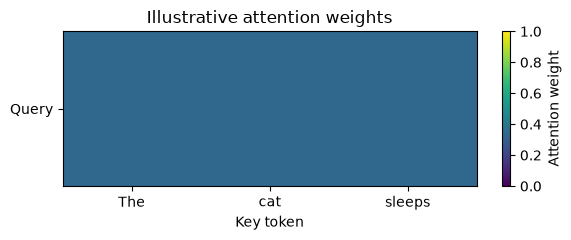

In [3]:
plt.figure(figsize=(6, 2.5))
plt.imshow(weights.detach().numpy(), cmap="viridis", aspect="auto", vmin=0, vmax=1)
plt.xticks(range(len(tokens)), tokens)
plt.yticks([0], ["Query"])
plt.colorbar(label="Attention weight")
plt.title("Illustrative attention weights")
plt.xlabel("Key token")
plt.tight_layout()
plt.show()

## 3. Implement scaled dot-product attention from scratch

Input shapes in this simple version:
- Q: `(batch, query_length, key_dim)`
- K: `(batch, key_length, key_dim)`
- V: `(batch, key_length, value_dim)`
- Output: `(batch, query_length, value_dim)`

An optional mask uses `True` for positions that should be blocked.

In [4]:
def scaled_dot_product_attention(query, key, value, mask=None):
    
    key_dim = query.size(-1)
    scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(key_dim)

    if mask is not None:
        scores = scores.masked_fill(mask, float("-inf"))

    attention_weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(attention_weights, value)
    return output, attention_weights


# Batch of 2, with 3 tokens and 4 features per token
q = torch.randn(2, 3, 4)
k = torch.randn(2, 3, 4)
v = torch.randn(2, 3, 6)

output, attn = scaled_dot_product_attention(q, k, v)
print("Output shape:", output.shape)       
print("Weights shape:", attn.shape)        
print("Weights sum per query (approximately 1):\n", attn.sum(dim=-1))

Output shape: torch.Size([2, 3, 6])
Weights shape: torch.Size([2, 3, 3])
Weights sum per query (approximately 1):
 tensor([[1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000]])


## 4. Causal attention mask

In autoregressive language models, token position *i* must not attend to future positions *j > i*. The mask below blocks the upper triangle. In the function above, `True` means blocked.

True = blocked position:
 tensor([[False,  True,  True,  True],
        [False, False,  True,  True],
        [False, False, False,  True],
        [False, False, False, False]])
Causal attention weights:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.1120, 0.8880, 0.0000, 0.0000],
        [0.1648, 0.2530, 0.5822, 0.0000],
        [0.0442, 0.4746, 0.4392, 0.0420]])


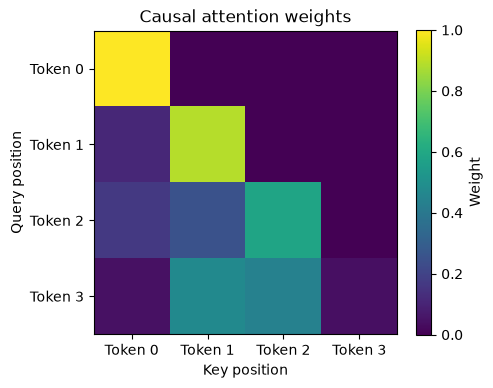

Check passed: future-token weights are zero.


In [5]:
sequence_length = 4
causal_mask = torch.triu(torch.ones(sequence_length, sequence_length, dtype=torch.bool), diagonal=1)
print("True = blocked position:\n", causal_mask)

q = torch.randn(1, sequence_length, 8)
k = torch.randn(1, sequence_length, 8)
v = torch.randn(1, sequence_length, 8)

causal_output, causal_weights = scaled_dot_product_attention(q, k, v, mask=causal_mask)
print("Causal attention weights:\n", causal_weights[0])

plt.figure(figsize=(5, 4))
plt.imshow(causal_weights[0].detach().numpy(), cmap="viridis", vmin=0, vmax=1)
plt.xticks(range(sequence_length), [f"Token {i}" for i in range(sequence_length)])
plt.yticks(range(sequence_length), [f"Token {i}" for i in range(sequence_length)])
plt.xlabel("Key position")
plt.ylabel("Query position")
plt.title("Causal attention weights")
plt.colorbar(label="Weight")
plt.tight_layout()
plt.show()

# Check: weights at future positions should be zero
assert torch.allclose(
    causal_weights[0][causal_mask],
    torch.zeros_like(causal_weights[0][causal_mask])
)
print("Check passed: future-token weights are zero.")

## 5. Use PyTorch `nn.MultiheadAttention`

Multi-head attention runs several attention heads in parallel. Each head can learn different relationships. PyTorch's module expects `(sequence_length, batch_size, embedding_dim)` by default; we set `batch_first=True` so inputs use `(batch_size, sequence_length, embedding_dim)`.

For self-attention, the same token embeddings are supplied as query, key, and value.

In [6]:
embedding_dim = 16
num_heads = 4
batch_size = 2
sequence_length = 5

mha = nn.MultiheadAttention(
    embed_dim=embedding_dim,
    num_heads=num_heads,
    batch_first=True
)

x = torch.randn(batch_size, sequence_length, embedding_dim)
mha_output, mha_weights = mha(
    query=x,
    key=x,
    value=x,
    need_weights=True,
    average_attn_weights=False
)

print("Input shape:", x.shape)                    
print("Output shape:", mha_output.shape)          
print("Per-head weights shape:", mha_weights.shape) 


Input shape: torch.Size([2, 5, 16])
Output shape: torch.Size([2, 5, 16])
Per-head weights shape: torch.Size([2, 4, 5, 5])


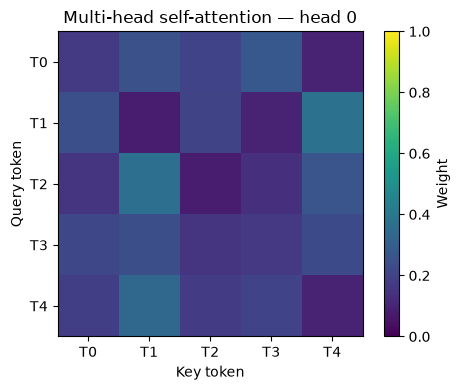

In [7]:
# Plot one attention head for the first item in the batch
head_index = 0
plt.figure(figsize=(5, 4))
plt.imshow(mha_weights[0, head_index].detach().numpy(), cmap="viridis", vmin=0, vmax=1)
plt.xticks(range(sequence_length), [f"T{i}" for i in range(sequence_length)])
plt.yticks(range(sequence_length), [f"T{i}" for i in range(sequence_length)])
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.title(f"Multi-head self-attention — head {head_index}")
plt.colorbar(label="Weight")
plt.tight_layout()
plt.show()

## 6. Multi-head attention with a causal mask

For `nn.MultiheadAttention`, `attn_mask=True` means that position is not allowed to attend. This matches the boolean mask convention used in the scratch implementation above.

In [8]:
causal_mask = torch.triu(
    torch.ones(sequence_length, sequence_length, dtype=torch.bool),
    diagonal=1
)

causal_mha_output, causal_mha_weights = mha(
    query=x,
    key=x,
    value=x,
    attn_mask=causal_mask,
    need_weights=True,
    average_attn_weights=False
)

print("Causal MHA output:", causal_mha_output.shape)
print("Causal MHA weights:", causal_mha_weights.shape)

# Verify no future positions receive attention
future_weights = causal_mha_weights.masked_select(
    causal_mask.view(1, 1, sequence_length, sequence_length)
)
print("Maximum future-position weight:", future_weights.max().item())
assert torch.allclose(future_weights, torch.zeros_like(future_weights), atol=1e-7)
print("Causal mask check passed.")

Causal MHA output: torch.Size([2, 5, 16])
Causal MHA weights: torch.Size([2, 4, 5, 5])
Maximum future-position weight: 0.0
Causal mask check passed.
